Running sweep on device: cuda


================ RUNNING CONFIG: {'layers': 4, 'heads': 4, 'd_model': 128, 'pos': 'learned'} ================
Epoch 01 | Train Loss: 2.5020 | Val Loss: 2.2874 | Val PPL: 9.85
Epoch 02 | Train Loss: 2.0451 | Val Loss: 1.9929 | Val PPL: 7.34
Epoch 03 | Train Loss: 1.7687 | Val Loss: 1.8453 | Val PPL: 6.33
Epoch 04 | Train Loss: 1.6127 | Val Loss: 1.7660 | Val PPL: 5.85
Epoch 05 | Train Loss: 1.5183 | Val Loss: 1.7054 | Val PPL: 5.50
Epoch 06 | Train Loss: 1.4539 | Val Loss: 1.6593 | Val PPL: 5.26
Epoch 07 | Train Loss: 1.4068 | Val Loss: 1.6432 | Val PPL: 5.17
Epoch 08 | Train Loss: 1.3711 | Val Loss: 1.6376 | Val PPL: 5.14
Epoch 09 | Train Loss: 1.3424 | Val Loss: 1.6319 | Val PPL: 5.11
Epoch 10 | Train Loss: 1.3178 | Val Loss: 1.6125 | Val PPL: 5.02

================ RUNNING CONFIG: {'layers': 2, 'heads': 4, 'd_model': 128, 'pos': 'learned'} ================
Epoch 01 | Train Loss: 2.5440 | Val Loss: 2.3257 | Val PPL: 10.23
Epoch 02 | Train Loss: 2.1218 |

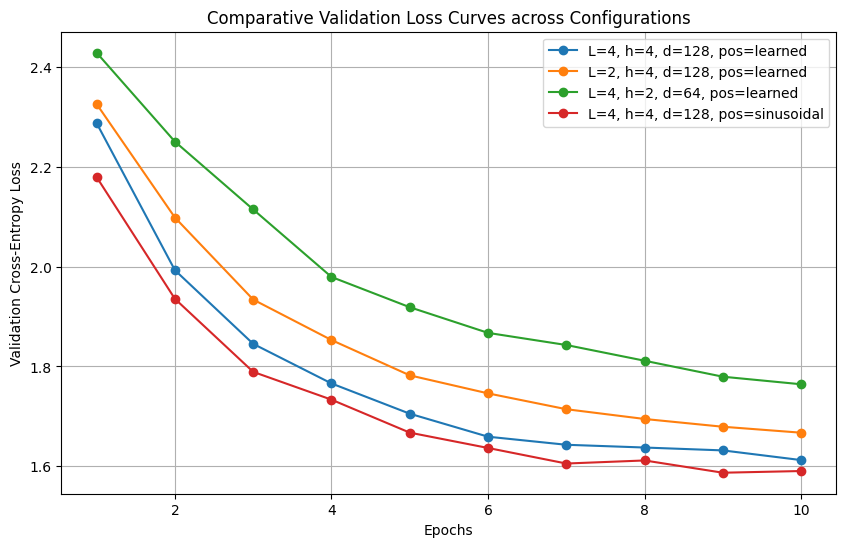


FINAL SUMMARY TABLE FOR REPORT
Config: {'layers': 4, 'heads': 4, 'd_model': 128, 'pos': 'learned'} 
 -> Final Val Loss: 1.6125 | Final Val PPL: 5.02

Config: {'layers': 2, 'heads': 4, 'd_model': 128, 'pos': 'learned'} 
 -> Final Val Loss: 1.6673 | Final Val PPL: 5.30

Config: {'layers': 4, 'heads': 2, 'd_model': 64, 'pos': 'learned'} 
 -> Final Val Loss: 1.7643 | Final Val PPL: 5.84

Config: {'layers': 4, 'heads': 4, 'd_model': 128, 'pos': 'sinusoidal'} 
 -> Final Val Loss: 1.5906 | Final Val PPL: 4.91



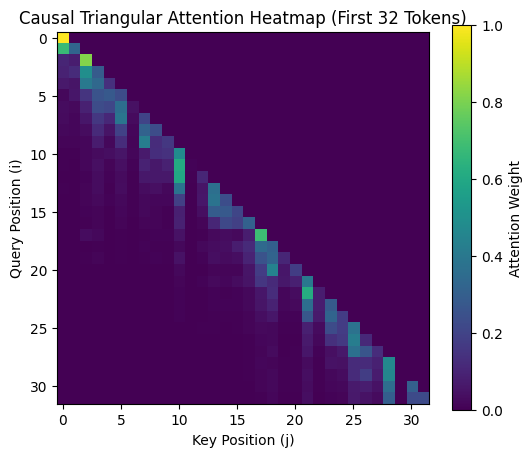


SAMPLE GENERATIONS (BEST MODEL)

--- [Greedy Decoding | Prompt: 'ROMEO:'] ---
ROMEO:
A ballad the common to the company of the state,
And then the company of the seasons of the state,
And thou shalt be the truth off the people
To seen


--- [Temperature = 0.5 | Prompt: 'To be, or not'] ---
To be, or not the way.

GLOUCESTER:
My lord, well the party to shall not die.

LEONTES:
I would have thee not to heart him.

LUCIO:
I hope, my lord, I say, fair no


--- [Temperature = 0.8 | Prompt: 'KING HENRY:'] ---
KING HENRY:
Well, why then I smengtle forth to do thee.

GLOUCESTER:
Then it will for her tidings the satilisa
From merader, in just thought in thence
I'll cae t


--- [Temperature = 1.2 | Prompt: 'What light through'] ---
What light through child fince quick.

ESCALUS:
Polantage his will promisonable hence of tvice, but
kitcheniles the truth together forth,--Margh Abol'sk tidic me
'I any


--- [Temperature = 0.8 | Prompt: 'My lord,'] ---
My lord, his course too doom.

LUCIO:
Farewell,

In [7]:
import os
import urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. DOWNLOAD FULL SHAKESPEARE DATASET
# ==========================================
file_path = "shakespeare.txt"
if not os.path.exists(file_path):
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    urllib.request.urlretrieve(url, file_path)
    print("Downloaded full Shakespeare dataset!")

with open(file_path, "r", encoding="utf-8") as f:
    raw_text = f.read()

# ==========================================
# 1. CHARACTER-LEVEL TOKENIZER & DATASET
# ==========================================
class CharTokenizer:
    def __init__(self, text):
        chars = sorted(list(set(text)))
        self.vocab_size = len(chars)
        self.stoi = {ch: i for i, ch in enumerate(chars)}
        self.itos = {i: ch for i, ch in enumerate(chars)}

    def encode(self, text):
        return [self.stoi[ch] for ch in text if ch in self.stoi]

    def decode(self, indices):
        return ''.join([self.itos[i] for i in indices])

class ShakespeareDataset(torch.utils.data.Dataset):
    def __init__(self, data_tensor, seq_len=128, stride=128):
        self.data = data_tensor
        self.seq_len = seq_len
        self.stride = stride

    def __len__(self):
        return max(0, (len(self.data) - self.seq_len - 1) // self.stride)

    def __getitem__(self, idx):
        start = idx * self.stride
        chunk = self.data[start : start + self.seq_len + 1]
        x = chunk[:-1]
        y = chunk[1:]
        return x, y

# ==========================================
# 2. POSITIONAL ENCODING & CAUSAL MHSA
# ==========================================
def get_sinusoidal_encoding(seq_len, d_model, device):
    pe = torch.zeros(seq_len, d_model, device=device)
    position = torch.arange(0, seq_len, dtype=torch.float, device=device).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2, device=device).float() * (-np.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe

class CausalMultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.last_attn_weights = None

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        mask = torch.triu(torch.full((T, T), float('-inf'), device=x.device), diagonal=1)
        scores = scores + mask

        attn_weights = F.softmax(scores, dim=-1)
        self.last_attn_weights = attn_weights.detach().cpu()

        attn_output = torch.matmul(attn_weights, v)
        attn_output = attn_output.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(attn_output)

# ==========================================
# 3. DECODER BLOCK & GPT TRANSFORMER
# ==========================================
class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalMultiHeadAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model)
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

class CausalDecoderTransformer(nn.Module):
    def __init__(self, vocab_size, seq_len, d_model, n_layers, n_heads, pos_type="learned"):
        super().__init__()
        self.pos_type = pos_type
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        if pos_type == "learned":
            self.pos_embedding = nn.Embedding(seq_len, d_model)
        self.blocks = nn.ModuleList([DecoderBlock(d_model, n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        if self.pos_type == "learned":
            pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
            pos_emb = self.pos_embedding(pos)
        else:
            pos_emb = get_sinusoidal_encoding(T, tok_emb.size(-1), idx.device)

        x = tok_emb + pos_emb
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        return self.head(x)

# ==========================================
# 4. DATA SETUP & HYPERPARAMETER SWEEP
# ==========================================
SEQ_LEN = 128
BATCH_SIZE = 64
EPOCHS = 10
LR = 1e-3

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running sweep on device: {device}\n")

tokenizer = CharTokenizer(raw_text)
full_data = torch.tensor(tokenizer.encode(raw_text), dtype=torch.long)
split_idx = int(0.9 * len(full_data))
train_data, val_data = full_data[:split_idx], full_data[split_idx:]

train_dataset = ShakespeareDataset(train_data, seq_len=SEQ_LEN, stride=64)
val_dataset = ShakespeareDataset(val_data, seq_len=SEQ_LEN, stride=128)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

configs = [
    {"layers": 4, "heads": 4, "d_model": 128, "pos": "learned"},
    {"layers": 2, "heads": 4, "d_model": 128, "pos": "learned"},
    {"layers": 4, "heads": 2, "d_model": 64,  "pos": "learned"},
    {"layers": 4, "heads": 4, "d_model": 128, "pos": "sinusoidal"},
]

results_summary = []
plt.figure(figsize=(10, 6))

best_model = None

for cfg in configs:
    print(f"\n================ RUNNING CONFIG: {cfg} ================")

    model = CausalDecoderTransformer(
        vocab_size=tokenizer.vocab_size,
        seq_len=SEQ_LEN,
        d_model=cfg["d_model"],
        n_layers=cfg["layers"],
        n_heads=cfg["heads"],
        pos_type=cfg["pos"]
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    val_losses = []

    for epoch in range(EPOCHS):
        model.train()
        total_train_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits.view(-1, tokenizer.vocab_size), y.view(-1))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)

        # Validation
        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                loss = criterion(logits.view(-1, tokenizer.vocab_size), y.view(-1))
                total_val_loss += loss.item()

        avg_val_loss = total_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        val_ppl = np.exp(avg_val_loss)

        print(f"Epoch {epoch+1:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val PPL: {val_ppl:.2f}")

    results_summary.append({
        "config": str(cfg),
        "final_val_loss": val_losses[-1],
        "final_val_ppl": np.exp(val_losses[-1])
    })

    # Save the best model (e.g., sinusoidal configuration) for text generation and heatmaps
    if cfg["pos"] == "sinusoidal" and cfg["layers"] == 4:
        best_model = model

    label_str = f"L={cfg['layers']}, h={cfg['heads']}, d={cfg['d_model']}, pos={cfg['pos']}"
    plt.plot(range(1, EPOCHS+1), val_losses, marker='o', label=label_str)

if best_model is None:
    best_model = model  # fallback

# Plot Comparative Loss Curves
plt.xlabel("Epochs")
plt.ylabel("Validation Cross-Entropy Loss")
plt.title("Comparative Validation Loss Curves across Configurations")
plt.legend()
plt.grid(True)
plt.show()

print("\n" + "="*40 + "\nFINAL SUMMARY TABLE FOR REPORT\n" + "="*40)
for res in results_summary:
    print(f"Config: {res['config']} \n -> Final Val Loss: {res['final_val_loss']:.4f} | Final Val PPL: {res['final_val_ppl']:.2f}\n")

# ==========================================
# 5. ATTENTION HEATMAP PLOT
# ==========================================
attn_map = best_model.blocks[0].attn.last_attn_weights[0, 0, :32, :32].numpy()
plt.figure(figsize=(6, 5))
plt.imshow(attn_map, cmap='viridis')
plt.colorbar(label="Attention Weight")
plt.title("Causal Triangular Attention Heatmap (First 32 Tokens)")
plt.xlabel("Key Position (j)")
plt.ylabel("Query Position (i)")
plt.show()

# ==========================================
# 6. TEXT GENERATION SAMPLES
# ==========================================
def generate_text(model, tokenizer, prompt, max_new_tokens=150, temperature=1.0, greedy=False, device='cpu'):
    model.eval()
    context = torch.tensor([tokenizer.encode(prompt)], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        context_cond = context[:, -128:]
        with torch.no_grad():
            logits = model(context_cond)[:, -1, :]
            if greedy:
                next_token = torch.argmax(logits, dim=-1, keepdim=True)
            else:
                probs = F.softmax(logits / temperature, dim=-1)
                next_token = torch.multinomial(probs, num_samples=1)
            context = torch.cat((context, next_token), dim=1)

    return tokenizer.decode(context[0].tolist())

prompts = ["ROMEO:", "To be, or not", "KING HENRY:", "What light through", "My lord,"]
configs_gen = [
    {"greedy": True, "temp": 1.0, "label": "Greedy Decoding"},
    {"greedy": False, "temp": 0.5, "label": "Temperature = 0.5"},
    {"greedy": False, "temp": 0.8, "label": "Temperature = 0.8"},
    {"greedy": False, "temp": 1.2, "label": "Temperature = 1.2"},
    {"greedy": False, "temp": 0.8, "label": "Temperature = 0.8"}
]

print("\n" + "="*50 + "\nSAMPLE GENERATIONS (BEST MODEL)\n" + "="*50)
for p, cfg in zip(prompts, configs_gen):
    out = generate_text(best_model, tokenizer, prompt=p, max_new_tokens=150,
                        temperature=cfg["temp"], greedy=cfg["greedy"], device=device)
    print(f"\n--- [{cfg['label']} | Prompt: '{p}'] ---\n{out}\n")